# Do they reach 7,000 steps on most days by avoiding long periods of inactivity?

**DATA3406 Assignment 2: Personal informatics, product notebook for driving problem Q1**

| | |
|---|---|
| **Team** | Ritishka Gupta (individual; Manager, Tracker and Analyst) |
| **Data** | FitBit Fitness Tracker Data (Furberg et al., 2016; Kaggle, CC0): `dailySteps_merged.csv`, `hourlySteps_merged.csv`, `minuteStepsWide_merged.csv` |
| **Reusable code** | [`q1_steps.py`](q1_steps.py), the pipeline module this notebook imports |
| **Process notebooks** | [Checkpoint 1: data exploration](Checkpoint%201-Ritishka%20Gupta-Step%20data%20exploration.ipynb) and [Checkpoint 2: data analysis for one person](Checkpoint%202-Ritishka%20Gupta-Step%20data%20analysis.ipynb) |

**Authorship statement.** All text and code in this notebook and in `q1_steps.py` are by **Ritishka Gupta**. I am the only member of my group, so there is no pair-programmed code. Cells that reuse or adapt code from my process notebooks say so in an *Author* line above them. Generative AI (Claude, Anthropic) helped draft code and text. The [final section](#18.-GenAI-usage) documents how, including a typical cell creation process.

**To run:** keep the three CSV files in `data/` next to this notebook and choose *Run All*. It takes about 30 seconds.

## 1. Introduction

**Driving problem.** Do the 33 people in this dataset achieve at least 7,000 steps on most days *by avoiding long periods of inactivity*?

**Why it matters.** About 7,000 steps a day is linked to a substantially lower risk of death (Paluch et al., 2022), and the Australian guidelines separately ask adults to *minimise and break up long periods of sitting*. If breaking up inactivity is how people reach their step goal, "get up more often" is practical, personal advice that a tracker could give.

The question has an **outcome** and a **route**, so I answer it in two parts:

- **Part A (the outcome):** does each person reach 7,000 steps on more than half of their valid days?
- **Part B (the route):** on the days a person reaches 7,000 steps, do they spend less time in long inactive periods than on their own other days? If so, what changes in their day?

**Answer in brief** (details and caveats in [Section 15](#15.-Answer-to-the-driving-problem)): **mostly yes.** 22 of the 29 people with enough data reach 7,000 steps on most days. For 18 of 21 people, goal days have less time in long inactive periods than their other days (a median of 91 minutes less). However, goal days do not have less inactive time *overall*. The same inactive time is broken into shorter spells by extra bouts of walking. People reach the goal by **interrupting** long inactive periods, not by being inactive less.

**Overview of the notebook** (the data pipeline runs from top to bottom):

| Section | Pipeline stage | What it does |
|---|---|---|
| 2–3 | Plan | Definitions with rationale, then the assumptions and predictions I made before the analysis |
| 4 | Setup | Imports and settings |
| 5 | Raw data | Loads the three files, checks their quality and shows a small example |
| 6 | Cleaned data | Reshapes the minute data and checks the three files against each other |
| 7 | Adherence | Decides which days and people have enough data, following Tang et al. (2018) |
| 8 | Descriptive analytics | Summarises a typical valid day |
| 9–12 | Analysis | Part A, Part B, how goal days differ, and why the comparison is within each person |
| 13 | Personal view | One person's month, minute by minute, for any chosen Id |
| 14 | Robustness | Repeats the key results under other definitions |
| 15–18 | Reporting | Answer, references and GenAI usage |

## 2. Definitions and rationale

The driving problem does not define "most days" or "long periods of inactivity", so these are my definitions. Each one is a field of `q1_steps.Definitions` (printed in Section 4), and Section 14 reruns the analysis with different values.

| Term | My definition | Why | Trade-off |
|---|---|---|---|
| Daily steps | Sum of the **minute** steps for the day | The same source as the inactivity measures. The daily file stops part-way through 12 May (Section 6) | Ignores steps that appear only in the daily file (rare; checked in Section 6) |
| Valid day | A complete day (1,440 minutes) with **at least 10 hours that contain a step** | Tang et al. (2018) show that conclusions depend on the valid-day rule. An hour-based rule removes days when the tracker was worn only briefly | A valid day can still include short periods without the tracker |
| Person with a verdict | At least **10 valid days** | With fewer days the share of goal days is too uncertain: with 6 days the 95% interval is about 60 percentage points wide | 4 people get no verdict |
| 7,000-step goal | At least 7,000 steps in the day | Given in the driving problem; Paluch et al. (2022) | |
| Most days | **More than half** of valid days; a stricter reading of **at least 5 days in 7** (≥ 71.4%) is also reported | The guidelines ask for activity on "most, preferably all, days" without giving a number | > 50% is the literal meaning |
| Clearly / uncertain | "Clearly" means the 95% Wilson interval of the share of goal days is entirely on one side of 50% | A person with 13 of 25 days (52%) is not clearly different from 50:50 | The interval assumes days are independent |
| Waking window | The **16 consecutive hours** in which the person most often has steps, estimated from their own data | No sleep data is supplied, and people's days start at different times (05:00 to 08:00 here) | The window cannot wrap past midnight |
| Inactive minute | **0–19 steps** in the minute | Tudor-Locke et al. (2018): 0 steps/min is non-movement and 1–19 is incidental stepping, not purposeful walking | Standing and shuffling counts as inactive |
| Walking minute | **20 or more steps** in the minute | The complement of an inactive minute | |
| Long period of inactivity | **60 or more** consecutive inactive minutes, between the first and last step of the day, inside the waking window | The guidelines do not give a length; 60 minutes is my choice, so 30 and 90 are also tested | Time before the first step and after the last is ignored: it is probably sleep or non-wear |
| Short inactive spell | 1–59 consecutive inactive minutes, same window | Shows whether inactivity is reduced or just broken up | |
| Within-person comparison | The person needs **at least 3 goal days and 3 other valid days** | Medians of one or two days are not meaningful | People who almost always (or never) reach the goal are left out of Part B |

## 3. Initial assumptions and predictions

Written **before** running this notebook on all 33 people. They are based on my [Checkpoint 1](Checkpoint%201-Ritishka%20Gupta-Step%20data%20exploration.ipynb) (three people) and [Checkpoint 2](Checkpoint%202-Ritishka%20Gupta-Step%20data%20analysis.ipynb) (Id 4558609924) results.

**Assumptions**

- **A1.** `Id` is the same person in all three files, and the data cover about one month (12 April to 12 May 2016).
- **A2.** A whole hour without any steps during the day is more likely to mean the tracker was off than that the person sat perfectly still. This is why the valid-day rule counts hours that contain a step.
- **A3.** The minute file is the most complete source. In Checkpoint 1 the daily file's 12 May was a partial day.
- **A4.** People sleep about 8 hours, so 16 waking hours is reasonable.
- **A5.** Within one person, goal days and other days are comparable. There is no information about work, holidays or illness, so differences are treated as differences in behaviour.

**Predictions**

- **P1.** About **60–70%** of people with enough data will reach 7,000 steps on most days. (Checkpoint 1: 2 of 3 people.)
- **P2.** Far fewer, about **40%**, will meet the strict 5-days-in-7 reading.
- **P3.** For **most people**, goal days will have less time in long inactive periods than their other days, but the day-level link will be **weak** (Checkpoint 2: rank correlation −0.33).
- **P4.** The extra steps on goal days will come mainly from **more minutes of walking**, not from walking faster.
- **P5.** The valid-day rule will **raise** the share of goal days, because days with little wear have low totals (Checkpoint 2: from 58% to 67%).

## 4. Setup

*Author: Ritishka Gupta.* Every import is in this cell. The pipeline functions live in `q1_steps.py`, so the notebook can focus on one step per cell.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.dates import DateFormatter, DayLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import q1_steps as q1

DATA_DIR = Path("data")
DEFS = q1.DEFS               # every definition from Section 2
EXAMPLE_ID = 4558609924      # the person from my Checkpoint 2; change it to view anyone

GOAL_COLOUR, MISS_COLOUR = "#2a78d6", "#eb6834"      # reached / did not reach 7,000
SHORT_COLOUR, LOW_WEAR_COLOUR = "#b8b6b0", "#8f8d87"  # short inactive spells; low-wear day
INCOMPLETE_COLOUR, NO_DATA_COLOUR = "#dcdad4", "#f4f3ef"
TEXT_COLOUR = "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.labelcolor": TEXT_COLOUR,
        "xtick.color": TEXT_COLOUR,
        "ytick.color": TEXT_COLOUR,
    }
)
pd.set_option("display.precision", 1)
DEFS

Definitions(step_goal=7000, min_valid_hours=10, waking_hours=16, inactive_max_steps=19, long_bout_min=60, most_days=0.5, strict_days=0.7142857142857143, min_valid_days=10, min_days_per_group=3)

## 5. Raw data

**Manual scrutiny (before loading).** In Checkpoint 1 I opened each CSV in Excel and found that:

- the daily and hourly files are "long" (one row per person per day or hour), while the minute file is "wide": one row per person per hour, with 60 columns `Steps00`–`Steps59`;
- the files cover different dates: the minute file starts at 00:00 on 13 April, the daily and hourly files on 12 April;
- some days have steps in the daily file but almost no steps in the minutes, which suggests the tracker was worn only briefly.

**Step:** load the three files and check missing values, duplicates, impossible values and the date range of each.

In [2]:
daily, hourly, minute_wide = q1.load_raw(DATA_DIR)
q1.quality_report(
    {
        "daily (one row per person-day)": (daily, "ActivityDay"),
        "hourly (one row per person-hour)": (hourly, "ActivityHour"),
        "minute, wide (one row per person-hour)": (minute_wide, "ActivityHour"),
    }
)

,rows,people,missing values,duplicate rows,duplicate Id-time keys,negative step values,first,last
daily (one row per person-day),940,33,0,0,0,0,2016-04-12 00:00:00,2016-05-12 00:00:00
hourly (one row per person-hour),22099,33,0,0,0,0,2016-04-12 00:00:00,2016-05-12 15:00:00
"minute, wide (one row per person-hour)",21645,33,0,0,0,0,2016-04-13 00:00:00,2016-05-13 08:00:00


**Result:** all three files contain the same 33 people, with no missing values, duplicate rows, repeated person-time keys or negative step counts, so no rows need repairing. The files differ only in coverage. The minute file runs from 13 April to the morning of 13 May, and the daily and hourly files from 12 April to 12 May. So **12 April has no minute data** and is not analysed.

**A small example.** The row below is one hour of the minute file for Id 4558609924, 29 April 2016, 15:00–15:59. I chose it because a single row shows everything the analysis has to tell apart: 32 minutes with no steps (31 of them in a row), 3 minutes of incidental stepping (8–19 steps), and 25 minutes of brisk walking at about 100 steps per minute. Under my definitions the first 35 minutes are one inactive run, and the walking that follows ends it.

In [3]:
example_hour = minute_wide[
    (minute_wide["Id"] == EXAMPLE_ID)
    & (minute_wide["ActivityHour"] == "2016-04-29 15:00")
].set_index(["Id", "ActivityHour"])
example_steps = example_hour.iloc[0]
kind = pd.cut(
    example_steps,
    [-1, 0, DEFS.inactive_max_steps, np.inf],
    labels=["0 steps", "1-19 steps (incidental)", "20+ steps (walking)"],
)
print(f"Hour total: {example_steps.sum():,} steps")
print(kind.value_counts(sort=False).rename("minutes").to_string())
example_hour  # the raw wide row

Hour total: 2,190 steps
(4558609924, 2016-04-29 15:00:00)
0 steps                    32
1-19 steps (incidental)     3
20+ steps (walking)        25


,,Steps00,Steps01,Steps02,Steps03,Steps04,Steps05,Steps06,Steps07,Steps08,Steps09,...,Steps50,Steps51,Steps52,Steps53,Steps54,Steps55,Steps56,Steps57,Steps58,Steps59
Id,ActivityHour,,,,,,,,,,,,,,,,,,,,,
4558609924,2016-04-29 15:00:00,0,0,0,0,0,0,0,0,0,0,...,98,62,99,101,100,97,98,97,99,101


## 6. Cleaned data

**Step:** reshape the wide minute file to one row per minute, and check that every person has an unbroken run of hours.

*Author: Ritishka Gupta. `q1.to_long` is the `person_minutes` function from my Checkpoint 2 notebook, rewritten for all people at once.*

In [4]:
minutes = q1.to_long(minute_wide)
hours_present = minute_wide.groupby("Id")["ActivityHour"].agg(["min", "max", "size"])
hours_expected = (hours_present["max"] - hours_present["min"]) / pd.Timedelta(hours=1) + 1
print(f"{len(minutes):,} person-minutes for {minutes['Id'].nunique()} people")
print(f"people with a gap in their hours: {(hours_expected != hours_present['size']).sum()}")
minutes.head()

1,298,700 person-minutes for 33 people
people with a gap in their hours: 0


,Id,Steps,Timestamp,Day,Hour
0,1503960366,4,2016-04-13 00:00:00,2016-04-13,0
1,1503960366,16,2016-04-13 00:01:00,2016-04-13,0
2,1503960366,0,2016-04-13 00:02:00,2016-04-13,0
3,1503960366,0,2016-04-13 00:03:00,2016-04-13,0
4,1503960366,0,2016-04-13 00:04:00,2016-04-13,0


**Result:** 1.3 million person-minutes with no gaps. When a person's data stop, they stop for good, so missing data appear only at the start and end of each person's record. Minutes that are absent are left as missing, not filled with zeros (assumption A2).

**Step:** check the three files against each other. If the hourly totals equal the sums of the minutes, and the daily totals equal the sums of each day's minutes, any of the files could supply daily steps.

In [5]:
minute_hour_totals = minute_wide.set_index(["Id", "ActivityHour"]).sum(axis=1)
hourly_totals = hourly.set_index(["Id", "ActivityHour"])["StepTotal"]
shared_hours = minute_hour_totals.index.intersection(hourly_totals.index)
hour_gap = hourly_totals[shared_hours] - minute_hour_totals[shared_hours]
print(f"hours in both files: {len(shared_hours):,}; hours that differ: {(hour_gap != 0).sum()}")

days_raw = q1.day_table(minutes, daily)
complete = days_raw[days_raw["Complete"]].dropna(subset=["DailyFileSteps"])
day_gap = complete["DailyFileSteps"] - complete["Steps"]
on_12_may = complete.index.get_level_values("Day") == "2016-05-12"
pd.DataFrame(
    {
        "complete days": [len(complete), on_12_may.sum()],
        "identical": [(day_gap == 0).sum(), (day_gap[on_12_may] == 0).sum()],
        "differ by 1-100 steps": [
            day_gap.abs().between(1, 100).sum(),
            day_gap[on_12_may].abs().between(1, 100).sum(),
        ],
        "differ by > 100 steps": [(day_gap.abs() > 100).sum(), (day_gap[on_12_may].abs() > 100).sum()],
        "daily file lower": [(day_gap < 0).sum(), (day_gap[on_12_may] < 0).sum()],
        "7,000 status changes": [
            ((complete["DailyFileSteps"] >= DEFS.step_goal) != complete["Goal"]).sum(),
            ((complete["DailyFileSteps"] >= DEFS.step_goal) != complete["Goal"])[on_12_may].sum(),
        ],
    },
    index=["all complete days", "of which 12 May"],
)

hours in both files: 21,307; hours that differ: 0


,complete days,identical,differ by 1-100 steps,differ by > 100 steps,daily file lower,"7,000 status changes"
all complete days,887,744,106,37,15,11
of which 12 May,15,2,0,13,13,4


**Interpretation:** the hourly and minute files agree **exactly** in every shared hour, so they are the same measurements at two resolutions. The daily file is different. Most complete days agree exactly or within a few steps, but **37 days differ by more than 100 steps**. **13 of these are 12 May**, where the daily file is much *lower* because its export stopped part-way through the day (the hourly file ends at 15:00 on 12 May). Most of the rest are days where the daily file is *higher*, which suggests steps added to the daily summary outside the minute record (for example, a later sync or a logged activity).

**Decision:** daily steps are the **sum of the minute data** (assumption A3 confirmed). This keeps steps and inactivity from the same source and recovers the full 12 May. The cost is that a few days may slightly under-count steps. Only 11 days of 887 change 7,000-step status, so the answer to Part A is not sensitive to this choice.

## 7. Adherence: which days and which people count?

Tang et al. (2018) showed that the definition of a *valid day* changes the conclusions drawn from tracker data. Because the tracker records only steps, a day of no steps could mean a day of sitting or a day the tracker was in a drawer. So before answering the question I analyse adherence in three steps:

1. **How:** classify every person-day as *valid*, *low-wear* (complete but fewer than 10 hours with a step) or *incomplete*, then show the month for every person (Figure 1).
2. **What I found:** compare the share of goal days and the number of people who meet "most days" under four rules for which days count.
3. **How it affects the results:** stated at the end of this section and carried into the answer.

*Author: Ritishka Gupta. The valid-day rule was chosen in Checkpoint 2 and is applied here to everyone.*

In [6]:
result = q1.analyse(minutes, daily)            # the whole pipeline in q1_steps.py
days = result["days"]
summary = q1.person_summary(result)
day_kind = pd.Series(
    np.select(
        [days["Valid"], days["Complete"]],
        ["valid", "low-wear (< 10 hours with steps)"],
        default="incomplete (< 1,440 minutes)",
    ),
    index=days.index,
)
day_kind.value_counts().rename("person-days").to_frame()

,person-days
valid,733
low-wear (< 10 hours with steps),155
"incomplete (< 1,440 minutes)",31


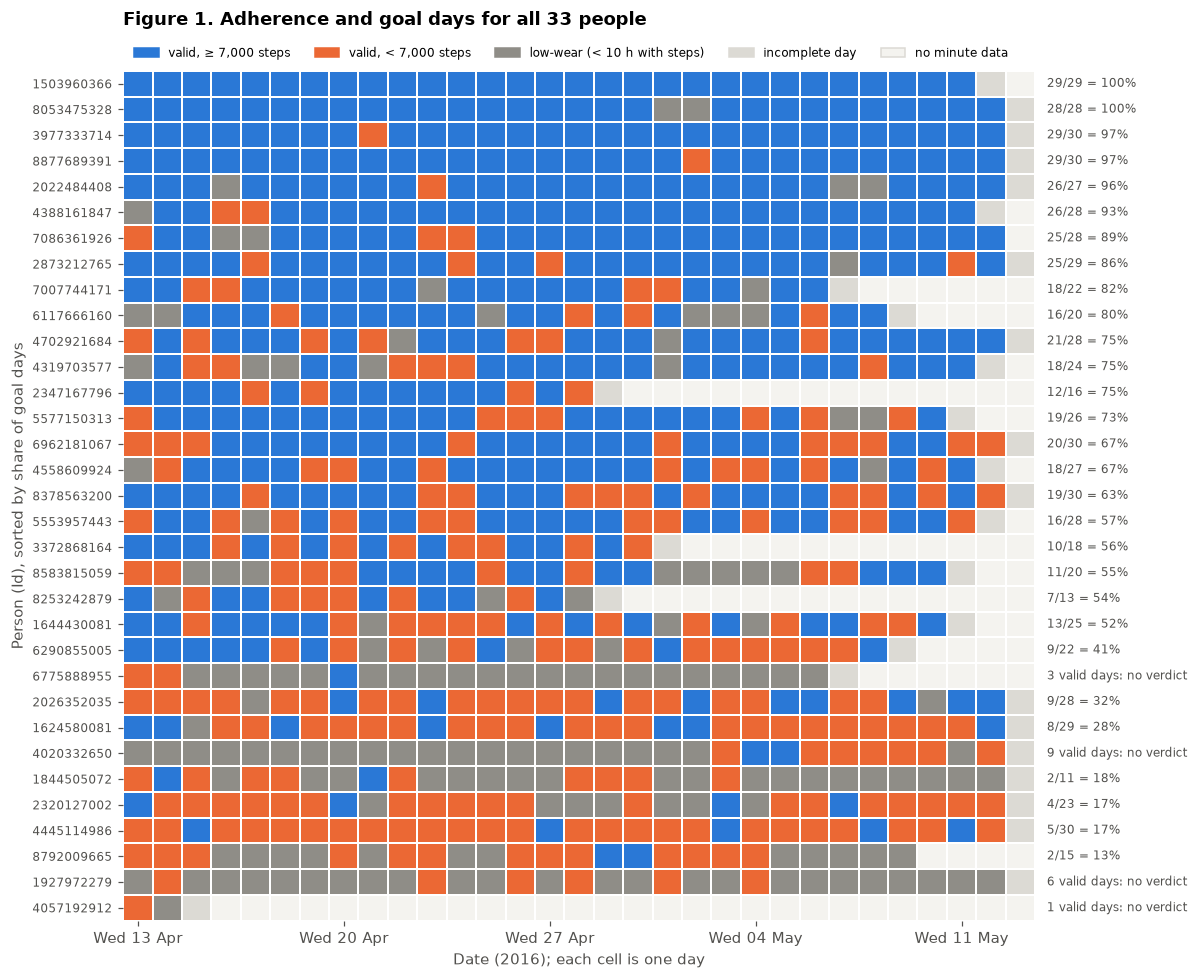

In [7]:
def plot_adherence_calendar(days, summary):
    """Figure 1: one row per person, one cell per day, coloured by wear and goal status."""
    status = np.select(
        [days["Valid"] & days["Goal"], days["Valid"], days["Complete"]], [4, 3, 2], default=1
    )
    grid = pd.Series(status, index=days.index).unstack().fillna(0)
    order = summary.assign(share=summary["% goal days"].fillna(-1)).sort_values(
        ["share", "valid days"], ascending=False
    ).index
    grid = grid.reindex(order)
    cmap = ListedColormap(
        [NO_DATA_COLOUR, INCOMPLETE_COLOUR, LOW_WEAR_COLOUR, MISS_COLOUR, GOAL_COLOUR]
    )
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.pcolormesh(grid.values, cmap=cmap, vmin=-0.5, vmax=4.5, edgecolors="white", linewidth=1)
    ax.invert_yaxis()
    ax.set_yticks(np.arange(len(grid)) + 0.5, [str(pid) for pid in grid.index], fontsize=8)
    weekly = range(0, grid.shape[1], 7)
    ax.set_xticks([i + 0.5 for i in weekly], [f"{grid.columns[i]:%a %d %b}" for i in weekly])
    for row, pid in enumerate(grid.index):
        info = summary.loc[pid]
        label = (
            f"{info['goal days']}/{info['valid days']} = {info['% goal days']:.0f}%"
            if info["valid days"] >= DEFS.min_valid_days
            else f"{info['valid days']} valid days: no verdict"
        )
        ax.text(grid.shape[1] + 0.4, row + 0.5, label, va="center", fontsize=8, color=TEXT_COLOUR)
    ax.set_xlabel("Date (2016); each cell is one day")
    ax.set_ylabel("Person (Id), sorted by share of goal days")
    ax.set_title("Figure 1. Adherence and goal days for all 33 people", loc="left", pad=30)
    legend = [
        Patch(color=GOAL_COLOUR, label="valid, ≥ 7,000 steps"),
        Patch(color=MISS_COLOUR, label="valid, < 7,000 steps"),
        Patch(color=LOW_WEAR_COLOUR, label="low-wear (< 10 h with steps)"),
        Patch(color=INCOMPLETE_COLOUR, label="incomplete day"),
        Patch(facecolor=NO_DATA_COLOUR, edgecolor=INCOMPLETE_COLOUR, label="no minute data"),
    ]
    ax.legend(handles=legend, ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=8)
    ax.spines[["left", "bottom"]].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_adherence_calendar(days, summary)

**What to see in Figure 1:** most rows are mainly blue and orange (valid days), but adherence varies a lot between people. **Grey cells** (days that do not count) cluster in a few people near the bottom: Ids 1927972279, 4020332650 and 6775888955 wore the tracker for 10 or more hours on fewer than 10 days, and 4057192912 stopped after 3 days. People with poor adherence also tend to have few goal days, so how these days are treated changes the answer. The pale cells on the right are where a person's minute data end: 12 May is incomplete for several people, and some people (for example Id 2347167796) stopped recording before the end of the month.

In [8]:
def goal_share_by_rule(goal_flags):
    """People with >= 10 counted days, how many meet 'most days', and the pooled share."""
    per_person = goal_flags.groupby(level="Id").agg(["size", "sum"])
    eligible = per_person[per_person["size"] >= DEFS.min_valid_days]
    share = eligible["sum"] / eligible["size"]
    return {
        "person-days counted": int(goal_flags.size),
        "% of those days >= 7,000": 100 * goal_flags.mean(),
        "people with >= 10 counted days": len(eligible),
        "people meeting 'most days'": int((share > DEFS.most_days).sum()),
    }


daily_file_goal = daily.set_index(["Id", "ActivityDay"])["StepTotal"].ge(DEFS.step_goal)
daily_file_worn = daily.set_index(["Id", "ActivityDay"])["StepTotal"].gt(0)
adherence_rules = pd.DataFrame(
    {
        "1. every day in the daily file": goal_share_by_rule(daily_file_goal),
        "2. daily file, 0-step days removed": goal_share_by_rule(daily_file_goal[daily_file_worn]),
        "3. complete days in the minute file": goal_share_by_rule(days.loc[days["Complete"], "Goal"]),
        "4. valid days (my rule)": goal_share_by_rule(days.loc[days["Valid"], "Goal"]),
    }
).T
adherence_rules.astype({col: int for col in adherence_rules.columns if not col.startswith("%")}).round(1)

,person-days counted,"% of those days >= 7,000",people with >= 10 counted days,people meeting 'most days'
1. every day in the daily file,940,53.5,32,18
"2. daily file, 0-step days removed",863,58.3,32,18
3. complete days in the minute file,888,54.2,32,19
4. valid days (my rule),733,65.1,29,22


**What I found:** the rule matters, as prediction **P5** expected. Counting every day in the daily file gives 54% goal days and 18 people who meet "most days". With my valid-day rule, the share of goal days rises to **65%** and **22 of 29** people meet "most days". Removing 0-step days (rule 2) helps a little, but many non-wear days are not zero: they contain a few hundred steps from brief wear, and only the hour-based rule removes them.

**How this affects the results:**

- The answer to Part A is about people's **behaviour on days they wore the tracker**, not about every calendar day. A rule that counts every day would mostly be measuring adherence.
- **4 people** (with 1, 3, 6 and 9 valid days) get no verdict. All four have low step counts on the days they did wear the tracker, so leaving them out probably makes the group look **more** active than it is. I report them rather than drop them silently.
- Part B compares each person's goal days with their own other days, on valid days only, so a person's wear habits are similar on both kinds of day.

In [9]:
summary[summary["valid days"] < DEFS.min_valid_days][
    ["days with minute data", "valid days", "goal days", "median steps"]
]

,days with minute data,valid days,goal days,median steps
Id,,,,
1927972279,31,6,0,2433.5
4020332650,31,9,2,5474.0
4057192912,3,1,0,5974.0
6775888955,25,3,1,5162.0


## 8. Descriptive analytics: what does a valid day look like?

**Step:** summarise the 733 valid person-days, and compare goal days with other days. The waking-window measures (awake, walking, inactive) cover the time between the first and last step inside each person's estimated 16-hour window.

In [10]:
valid = days[days["Valid"]].assign(
    ShortInactive=lambda d: d["InactiveMinutes"] - d["LongBoutMinutes"],
    WalkingAwake=lambda d: d["AwakeMinutes"] - d["InactiveMinutes"],
)
measures = {
    "Steps": "steps",
    "ActiveMinutes": "walking minutes (whole day)",
    "AwakeMinutes": "minutes from first to last step",
    "InactiveMinutes": "inactive minutes (awake)",
    "LongBouts": "long inactive periods (count)",
    "LongBoutMinutes": "minutes in long inactive periods",
    "LongestInactive": "longest inactive run (min)",
}
descriptive = pd.concat(
    {
        "all valid days": valid[list(measures)].median(),
        "goal days": valid.loc[valid["Goal"], list(measures)].median(),
        "other days": valid.loc[~valid["Goal"], list(measures)].median(),
    },
    axis=1,
).rename(index=measures)
descriptive.loc["days"] = [len(valid), valid["Goal"].sum(), (~valid["Goal"]).sum()]
print(f"minutes with zero steps (all minutes, all people): {(minutes['Steps'] == 0).mean():.0%}")
print(f"steps taken in walking minutes (>= 20 steps/min): {valid['ActiveSteps'].sum() / valid['Steps'].sum():.0%}")
print(f"goal days with no long inactive period: {(valid.loc[valid['Goal'], 'LongBouts'] == 0).mean():.0%}")
descriptive.round(0).astype(int).rename_axis("median per valid day")

minutes with zero steps (all minutes, all people): 85%
steps taken in walking minutes (>= 20 steps/min): 87%
goal days with no long inactive period: 14%


,all valid days,goal days,other days
median per valid day,,,
steps,8857,10611,4962
walking minutes (whole day),144,170,90
minutes from first to last step,879,894,849
inactive minutes (awake),730,720,758
long inactive periods (count),2,2,3
minutes in long inactive periods,213,182,302
longest inactive run (min),100,92,130
days,733,477,256


In [11]:
wake_counts = summary["wake start"].value_counts().sort_index()
wake_counts.index = [f"{h:02d}:00-{h + DEFS.waking_hours - 1:02d}:59" for h in wake_counts.index]
wake_counts.rename("people").to_frame().T

,05:00-20:59,06:00-21:59,07:00-22:59,08:00-23:59
people,1,13,4,15


**Interpretation:** the median valid day has about 8,900 steps, yet **85% of all minutes have zero steps**, and 87% of steps are taken in walking minutes. Walking comes in short bursts. Goal days have about 1.9 times the walking minutes of other days, and fewer and shorter long inactive periods. But the typical goal day still contains **two** long inactive periods, and only 14% of goal days have none, so these periods are reduced, not avoided altogether. Estimated waking windows start between 05:00 and 08:00, which is why a single fixed window (as in my Checkpoint 1) would misjudge some people. These are pooled figures, so very active people contribute many goal days. Sections 10–11 therefore compare each person with themselves.

## 9. Part A: do they reach 7,000 steps on most days?

**Method.** For each person with at least 10 valid days, the share of goal days is $\hat p = k/n$, where $k$ is the number of goal days and $n$ the number of valid days. One month is a small sample, so I put a 95% **Wilson score interval** around $\hat p$. It behaves well for small $n$ and for shares near 0% or 100%:

$$
\frac{\hat p + \frac{z^2}{2n} \;\pm\; z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \qquad z = 1.96.
$$

A person meets "most days" if $\hat p > 0.5$, and does so **clearly** if the whole interval is above 0.5. For example, with $k = 18$ and $n = 27$ (Id 4558609924), $\hat p = 0.667$ and the interval is 0.478 to 0.814. That is "yes", but not clearly.

*Author: Ritishka Gupta (`q1.wilson_interval`, `q1.person_summary`).*

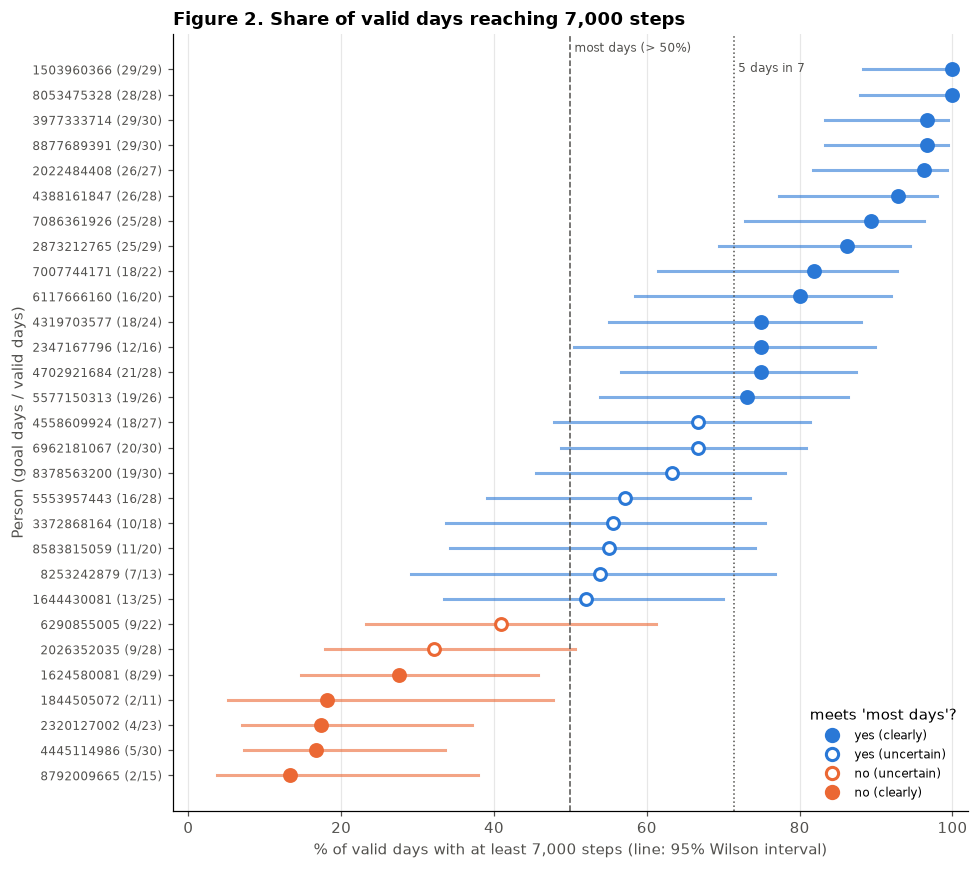

In [12]:
def plot_goal_share(summary):
    """Figure 2: share of valid days >= 7,000 steps with a 95% interval, one row per person."""
    rated = summary[summary["valid days"] >= DEFS.min_valid_days].sort_values("% goal days")
    style = {
        "yes (clearly)": dict(color=GOAL_COLOUR, fill=True),
        "yes (uncertain)": dict(color=GOAL_COLOUR, fill=False),
        "no (uncertain)": dict(color=MISS_COLOUR, fill=False),
        "no (clearly)": dict(color=MISS_COLOUR, fill=True),
    }
    fig, ax = plt.subplots(figsize=(9, 8))
    for y, (pid, row) in enumerate(rated.iterrows()):
        s = style[row["verdict"]]
        ax.plot([row["95% CI low"], row["95% CI high"]], [y, y], color=s["color"], linewidth=2, alpha=0.6)
        ax.scatter(
            row["% goal days"], y, s=60, zorder=3, linewidth=2,
            color=s["color"] if s["fill"] else "white", edgecolor=s["color"],
        )
    ax.axvline(100 * DEFS.most_days, color=TEXT_COLOUR, linestyle="--", linewidth=1)
    ax.axvline(100 * DEFS.strict_days, color=TEXT_COLOUR, linestyle=":", linewidth=1)
    ax.text(100 * DEFS.most_days, len(rated) - 0.3, " most days (> 50%)", fontsize=8, color=TEXT_COLOUR)
    ax.text(100 * DEFS.strict_days, len(rated) - 1.1, " 5 days in 7", fontsize=8, color=TEXT_COLOUR)
    ax.set_yticks(range(len(rated)), [f"{pid} ({row['goal days']}/{row['valid days']})" for pid, row in rated.iterrows()], fontsize=8)
    ax.set_xlim(-2, 102)
    ax.set_xlabel("% of valid days with at least 7,000 steps (line: 95% Wilson interval)")
    ax.set_ylabel("Person (goal days / valid days)")
    ax.set_title("Figure 2. Share of valid days reaching 7,000 steps", loc="left")
    handles = [
        Line2D([], [], marker="o", linestyle="", markersize=8, markeredgewidth=2, label=label,
               color=s["color"], markerfacecolor=s["color"] if s["fill"] else "white")
        for label, s in style.items()
    ]
    ax.legend(handles=handles, title="meets 'most days'?", loc="lower right", frameon=False, fontsize=8)
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_goal_share(summary)

In [13]:
rated = summary[summary["valid days"] >= DEFS.min_valid_days]
part_a = rated["verdict"].value_counts().reindex(
    ["yes (clearly)", "yes (uncertain)", "no (uncertain)", "no (clearly)"]
).rename("people").to_frame()
part_a.loc["total with a verdict"] = len(rated)
print(
    f"Meet 'most days' (> 50%): {rated['verdict'].str.startswith('yes').sum()} of {len(rated)} people; "
    f"strict 5 in 7 (>= 71.4%): {(rated['% goal days'] >= 100 * DEFS.strict_days).sum()} of {len(rated)}"
)
part_a

Meet 'most days' (> 50%): 22 of 29 people; strict 5 in 7 (>= 71.4%): 14 of 29


,people
verdict,
yes (clearly),14
yes (uncertain),8
no (uncertain),2
no (clearly),5
total with a verdict,29


**What to see in Figure 2:** filled dots have intervals that lie entirely on one side of the dashed 50% line, so their verdict is clear. **22 of 29 people** are to the right of the line (blue), and **14** of them clearly. 7 people are to the left (orange), 5 of them clearly. The 8 hollow blue dots are people whose share is above 50% but could plausibly be a 50:50 pattern; one month is not long enough to be sure. Only **14 of 29** reach the stricter dotted 5-in-7 line.

**Prediction check:** P1 is **confirmed and slightly exceeded**: 22 of 29 is 76%, above my 60–70%. P2 is **roughly confirmed**: 14 of 29 (48%) meet 5 days in 7, a little more than I predicted.

## 10. Part B: is it by avoiding long periods of inactivity?

**Why compare each person with themselves.** People differ in jobs, fitness and how they wear the tracker. If I compared active *people* with inactive *people*, these differences would be mixed into the answer. The driving problem asks how people reach the goal, so for each person I compare **their goal days with their own other days**. This needs at least 3 of each, which leaves 21 people.

**Method.** For person $i$, let $d_i$ be the median minutes in long inactive periods on goal days minus the median on other days. If goal days had nothing to do with long inactivity, each $d_i$ would be equally likely to be negative or positive. The **sign test** asks how surprising the observed number of negative differences $m$ out of $n$ would be under that 50:50 assumption:

$$
P = 2 \sum_{j=0}^{\min(m,\,n-m)} \binom{n}{j}\left(\tfrac12\right)^{n}.
$$

*Author: Ritishka Gupta (`q1.within_person`, `q1.sign_test`). Based on the goal-day comparison in my Checkpoint 2 notebook.*

In [14]:
within = q1.within_person(result)
lower = (within["long-inactive min difference"] < 0).sum()
n_people = len(within)
print(f"People with >= 3 goal and >= 3 other valid days: {n_people}")
print(f"Less time in long inactive periods on goal days: {lower} of {n_people} "
      f"(sign test P = {q1.sign_test(lower, n_people):.4f})")
print(f"Median difference: {within['long-inactive min difference'].median():.0f} min per day")
print(f"Rank correlation (long-inactive minutes vs steps) is negative for "
      f"{(within['rank corr'] < 0).sum()} of {n_people}; median {within['rank corr'].median():.2f}")

People with >= 3 goal and >= 3 other valid days: 21
Less time in long inactive periods on goal days: 18 of 21 (sign test P = 0.0015)
Median difference: -91 min per day
Rank correlation (long-inactive minutes vs steps) is negative for 18 of 21; median -0.40


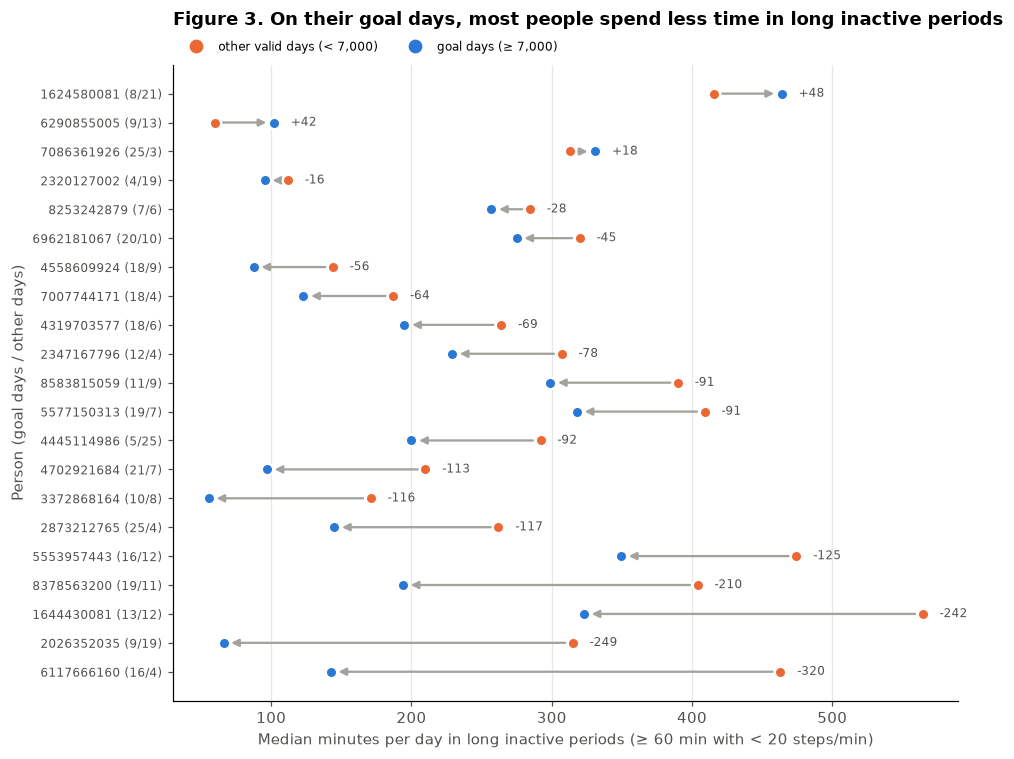

In [15]:
def plot_within_person(within):
    """Figure 3: each person's median minutes in long inactive periods, goal vs other days."""
    order = within.sort_values("long-inactive min difference")
    fig, ax = plt.subplots(figsize=(9, 7))
    for y, (pid, row) in enumerate(order.iterrows()):
        other, goal = row["LongBoutMinutes (other)"], row["LongBoutMinutes (goal)"]
        ax.annotate("", xy=(goal, y), xytext=(other, y),
                    arrowprops=dict(arrowstyle="-|>", color="#a3a29d", linewidth=1.5, shrinkA=5, shrinkB=5))
        ax.scatter(other, y, s=55, color=MISS_COLOUR, zorder=3, edgecolor="white", linewidth=1.5)
        ax.scatter(goal, y, s=55, color=GOAL_COLOUR, zorder=3, edgecolor="white", linewidth=1.5)
        ax.text(max(other, goal) + 12, y, f"{row['long-inactive min difference']:+.0f}",
                va="center", fontsize=8, color=TEXT_COLOUR)
    ax.set_yticks(range(len(order)), [f"{pid} ({row['goal days']:.0f}/{row['other days']:.0f})" for pid, row in order.iterrows()], fontsize=8)
    ax.set_xlabel("Median minutes per day in long inactive periods (≥ 60 min with < 20 steps/min)")
    ax.set_ylabel("Person (goal days / other days)")
    ax.set_title("Figure 3. On their goal days, most people spend less time in long inactive periods", loc="left", pad=26)
    ax.legend(
        handles=[
            Line2D([], [], marker="o", linestyle="", color=MISS_COLOUR, markersize=8, label="other valid days (< 7,000)"),
            Line2D([], [], marker="o", linestyle="", color=GOAL_COLOUR, markersize=8, label="goal days (≥ 7,000)"),
        ],
        loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8,
    )
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_within_person(within)

**What to see in Figure 3:** each arrow runs from a person's other days (orange) to their goal days (blue), and the number is the change in minutes. **18 of 21 arrows point left**: on goal days these people spent less time in long inactive periods, typically **about 1.5 hours less** (median −91 minutes). Only 3 people (Ids 1624580081, 6290855005 and 7086361926) point right, by 18 to 48 minutes. If goal days were unrelated to long inactivity, a split as uneven as 18 to 3 would happen by chance only about 1.5 times in 1,000 (sign test P = 0.0015).

Prediction **P3 is confirmed**. The pattern holds for most people, but within each person the day-to-day link is moderate (median rank correlation −0.40), because some goal days still contain several long inactive periods.

## 11. What changes on a goal day: less inactivity, or broken-up inactivity?

Figure 3 shows *less time in long inactive periods* on goal days. That could happen in two different ways:

- **(a) less inactivity overall:** the person is simply inactive for less of the day; or
- **(b) the same inactivity, broken up:** inactive time stays about the same, but bouts of walking split long periods into short ones.

**Step:** for each of the 21 people, split their waking time (first to last step) into **walking**, **short inactive spells** (under 60 minutes) and **long inactive periods**, and average each over their goal days and their other days.

In [16]:
parts = ["WalkingAwake", "ShortInactive", "LongBoutMinutes", "InactiveMinutes", "AwakeMinutes"]
in_part_b = valid.index.get_level_values("Id").isin(within.index)
person_means = valid[in_part_b].groupby(["Id", "Goal"])[parts].mean().unstack("Goal")
change = person_means.xs(True, axis=1, level="Goal") - person_means.xs(False, axis=1, level="Goal")
anatomy = pd.DataFrame(
    {
        "other days (mean of people)": person_means.xs(False, axis=1, level="Goal").mean(),
        "goal days (mean of people)": person_means.xs(True, axis=1, level="Goal").mean(),
        "median change per person": change.median(),
        "people with more on goal days": (change > 0).sum().astype(str) + f" of {len(change)}",
    }
).rename(
    index={
        "WalkingAwake": "walking (min)",
        "ShortInactive": "short inactive spells (min)",
        "LongBoutMinutes": "long inactive periods (min)",
        "InactiveMinutes": "all inactive time (min)",
        "AwakeMinutes": "first to last step (min)",
    }
)
anatomy.round(0)

,other days (mean of people),goal days (mean of people),median change per person,people with more on goal days
walking (min),87.0,159.0,68.0,21 of 21
short inactive spells (min),429.0,506.0,79.0,20 of 21
long inactive periods (min),302.0,209.0,-91.0,4 of 21
all inactive time (min),731.0,715.0,-54.0,8 of 21
first to last step (min),818.0,874.0,45.0,19 of 21


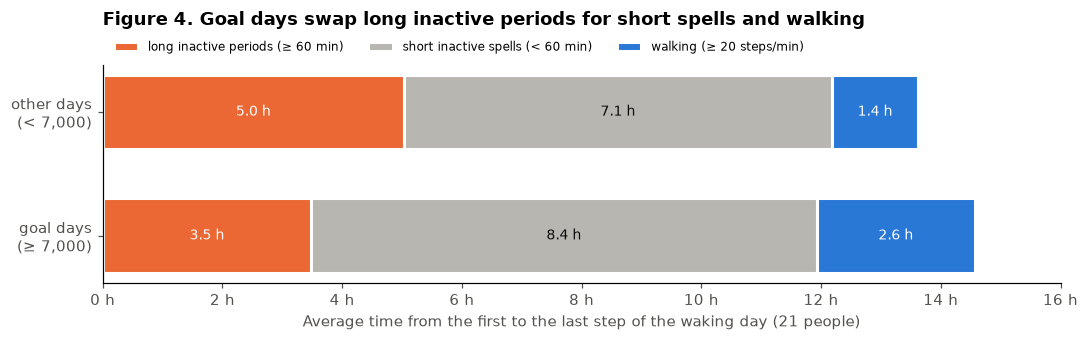

In [17]:
def plot_day_anatomy(anatomy):
    """Figure 4: how the waking day is split on other days and on goal days."""
    rows = ["long inactive periods (min)", "short inactive spells (min)", "walking (min)"]
    colours = [MISS_COLOUR, SHORT_COLOUR, GOAL_COLOUR]
    labels = ["long inactive periods (≥ 60 min)", "short inactive spells (< 60 min)", "walking (≥ 20 steps/min)"]
    columns = ["other days (mean of people)", "goal days (mean of people)"]
    fig, ax = plt.subplots(figsize=(10, 3.2))
    for y, column in enumerate(columns):
        left = 0
        for row, colour, label in zip(rows, colours, labels):
            width = anatomy.loc[row, column]
            ax.barh(y, width, left=left, color=colour, edgecolor="white", linewidth=2, height=0.6,
                    label=label if y == 0 else None)
            ax.text(left + width / 2, y, f"{width / 60:.1f} h", ha="center", va="center", fontsize=9,
                    color="white" if colour != SHORT_COLOUR else "#0b0b0b")
            left += width
    ax.set_yticks([0, 1], ["other days\n(< 7,000)", "goal days\n(≥ 7,000)"])
    ax.set_xticks(range(0, 1001, 120), [f"{m // 60} h" for m in range(0, 1001, 120)])
    ax.set_xlabel("Average time from the first to the last step of the waking day (21 people)")
    ax.set_title("Figure 4. Goal days swap long inactive periods for short spells and walking", loc="left", pad=26)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=8)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


plot_day_anatomy(anatomy)

**What to see in Figure 4:** compare the **orange** segments. Long inactive periods shrink by about an hour and a half on goal days, but the **grey** segment of short inactive spells grows by more than an hour, so the total length of the two inactive segments hardly changes. The **blue** walking segment roughly doubles, and the waking day is a little longer.

The table confirms this person by person. All-inactive time falls by a median of only 54 minutes and is *higher* on goal days for 8 of 21 people. Short inactive spells are higher on goal days for **20 of 21 people**. So the evidence supports route **(b)**: on goal days people are inactive for roughly as long as usual, but they **interrupt** that inactivity with walking, which turns long periods into short ones. This is the best evidence in the data for the "by avoiding long periods of inactivity" part of the driving problem. It is also the clearest message for a person using their tracker: *you don't need to sit less in total; get up more often*.

## 12. Where do the extra steps come from: more walking, or faster walking?

Steps taken while walking, $S_w$, equal walking minutes $W$ times the average cadence while walking, $c$ (steps per walking minute): $S_w = W \times c$. Taking logs turns this into a sum, so the **gap between goal days and other days splits exactly into two parts**:

$$
\underbrace{\Delta \ln S_w}_{\text{more steps while walking}} \;=\; \underbrace{\Delta \ln W}_{\text{more walking minutes}} \;+\; \underbrace{\Delta \ln c}_{\text{faster walking}},
$$

where $\Delta$ is the mean over a person's goal days minus the mean over their other days. Walking minutes contain 87% of all steps on valid days, so $S_w$ is close to total steps. Figure 5 shows each part as a ratio, $e^{\Delta}$ (for example ×2 means "twice as many on goal days").

*Author: Ritishka Gupta (`q1.within_person`).*

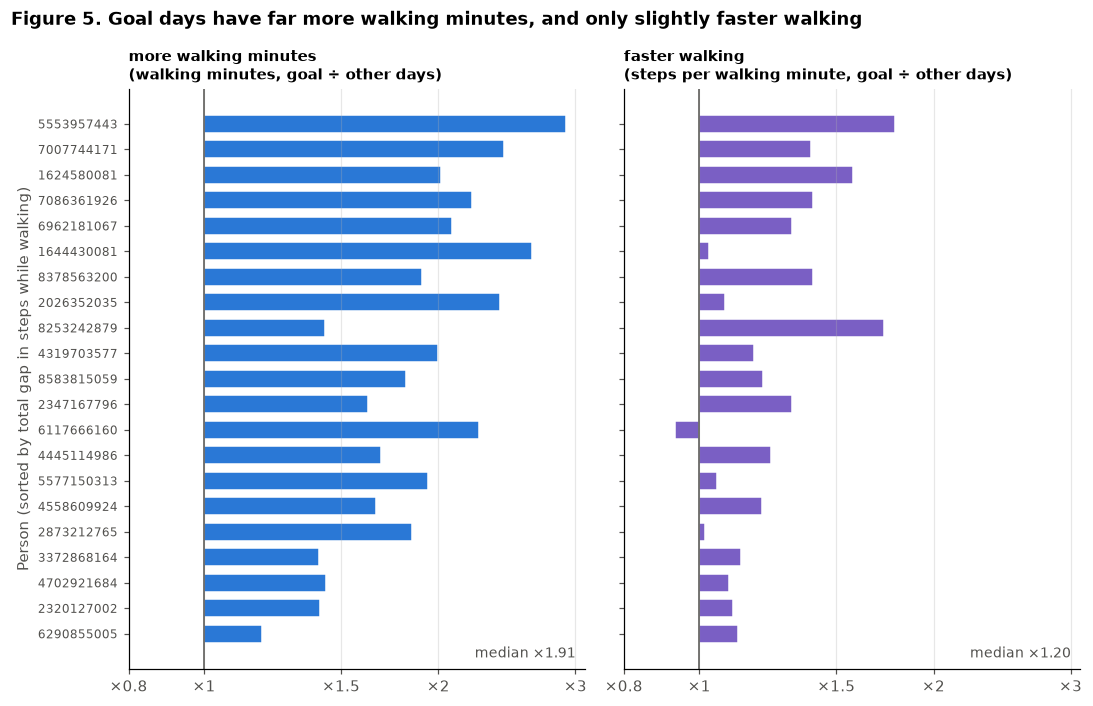

Median share of the gap from more walking minutes: 73% (over 50% for 20 of 21 people)


In [18]:
def plot_step_sources(within):
    """Figure 5: goal-day / other-day ratio of walking minutes and of cadence, per person."""
    order = within.sort_values("gap lnActiveSteps")
    ratios = {
        "more walking minutes\n(walking minutes, goal ÷ other days)": np.exp(order["gap lnActiveMinutes"]),
        "faster walking\n(steps per walking minute, goal ÷ other days)": np.exp(order["gap lnCadence"]),
    }
    fig, axes = plt.subplots(1, 2, figsize=(10, 6.5), sharey=True, sharex=True)
    for ax, (title, ratio), colour in zip(axes, ratios.items(), [GOAL_COLOUR, "#7a5fc4"]):
        ax.barh(range(len(ratio)), ratio - 1, left=1, color=colour, height=0.7, edgecolor="white", linewidth=1)
        ax.axvline(1, color=TEXT_COLOUR, linewidth=1)
        ax.set_title(title, loc="left", fontsize=10)
        ax.set_xscale("log")
        ax.set_xticks([0.8, 1, 1.5, 2, 3], ["×0.8", "×1", "×1.5", "×2", "×3"])
        ax.minorticks_off()
        ax.grid(axis="x", alpha=0.3)
        ax.text(0.98, 0.02, f"median ×{ratio.median():.2f}", transform=ax.transAxes, ha="right", fontsize=9, color=TEXT_COLOUR)
    axes[0].set_yticks(range(len(order)), order.index.astype(str), fontsize=8)
    axes[0].set_ylabel("Person (sorted by total gap in steps while walking)")
    fig.suptitle("Figure 5. Goal days have far more walking minutes, and only slightly faster walking",
                 x=0.01, ha="left", fontweight="bold", fontsize=12)
    plt.tight_layout()
    plt.show()


plot_step_sources(within)
print(f"Median share of the gap from more walking minutes: "
      f"{within['share of gap from more walking minutes'].median():.0%} "
      f"(over 50% for {(within['share of gap from more walking minutes'] > 0.5).sum()} of {len(within)} people)")

**What to see in Figure 5:** the blue bars (left) are much longer than the purple bars (right) for almost everyone. On goal days people walk for about **1.9 times as many minutes**, but walk only about **1.2 times as fast**. For the median person, **73%** of the extra steps come from more walking minutes. This is true for 20 of 21 people; the exception is Id 8253242879, who walks faster on goal days. Prediction **P4 is confirmed**. Together with Figure 4, this means goal days come from **more, separate bouts of walking** that break up inactive time, not from a single faster walk.

## 13. Why the within-person comparison matters, and one person's month

**Step:** compare *people* instead of days. Does a person who usually has a lot of long inactive time reach the goal less often?

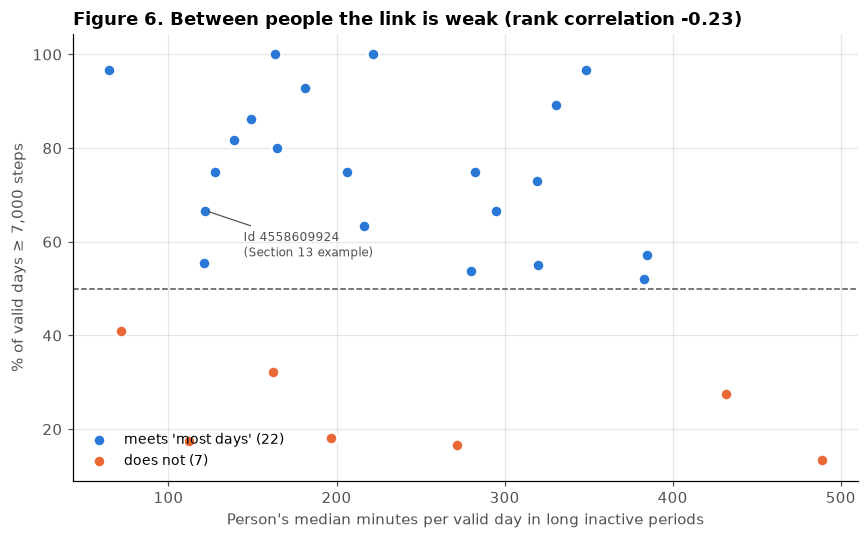

In [19]:
def plot_between_people(summary, example_id):
    """Figure 6: each person's typical long-inactive time against their share of goal days."""
    rated = summary[summary["valid days"] >= DEFS.min_valid_days]
    rho = q1.rank_correlation(rated["median long-inactive min"], rated["% goal days"])
    fig, ax = plt.subplots(figsize=(8, 5))
    meets = rated["% goal days"] > 100 * DEFS.most_days
    for flag, colour, label in [(True, GOAL_COLOUR, "meets 'most days'"), (False, MISS_COLOUR, "does not")]:
        part = rated[meets == flag]
        ax.scatter(part["median long-inactive min"], part["% goal days"], s=60, color=colour,
                   edgecolor="white", linewidth=1.5, label=f"{label} ({len(part)})", zorder=3)
    ex = rated.loc[example_id]
    ax.annotate(f"Id {example_id}\n(Section 13 example)", (ex["median long-inactive min"], ex["% goal days"]),
                xytext=(25, -30), textcoords="offset points", fontsize=8, color=TEXT_COLOUR,
                arrowprops=dict(arrowstyle="-", color=TEXT_COLOUR, linewidth=0.8))
    ax.axhline(100 * DEFS.most_days, color=TEXT_COLOUR, linestyle="--", linewidth=1)
    ax.set_xlabel("Person's median minutes per valid day in long inactive periods")
    ax.set_ylabel("% of valid days ≥ 7,000 steps")
    ax.set_title(f"Figure 6. Between people the link is weak (rank correlation {rho:.2f})", loc="left")
    ax.legend(frameon=False, loc="lower left", fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return rho


between_rho = plot_between_people(summary, EXAMPLE_ID)

**What to see in Figure 6:** there is no clear downward slope. Some people with **more than 5 hours** of long inactive periods on a typical day still reach 7,000 steps on almost every day (for example Id 3977333714, 97% of days), while Id 6290855005, with only about an hour, reaches it on fewer than half of their days. The between-person rank correlation is only −0.23, much weaker than the within-person pattern in Figure 3.

This is why Part B compares each person with themselves. Someone with a desk job may have long sitting periods every day and still reach 7,000 steps with a walk to and from work. The driving problem is about how a person reaches the goal, and that only shows when their good days are compared with their own bad days.

**One person's month.** The next figure is the personal-informatics view: what a single person would see about their own month. It works for any Id; change `EXAMPLE_ID` in Section 4.

*Author: Ritishka Gupta. Adapted from `plot_day_timeline` in my Checkpoint 2 notebook; it now uses the all-people pipeline.*

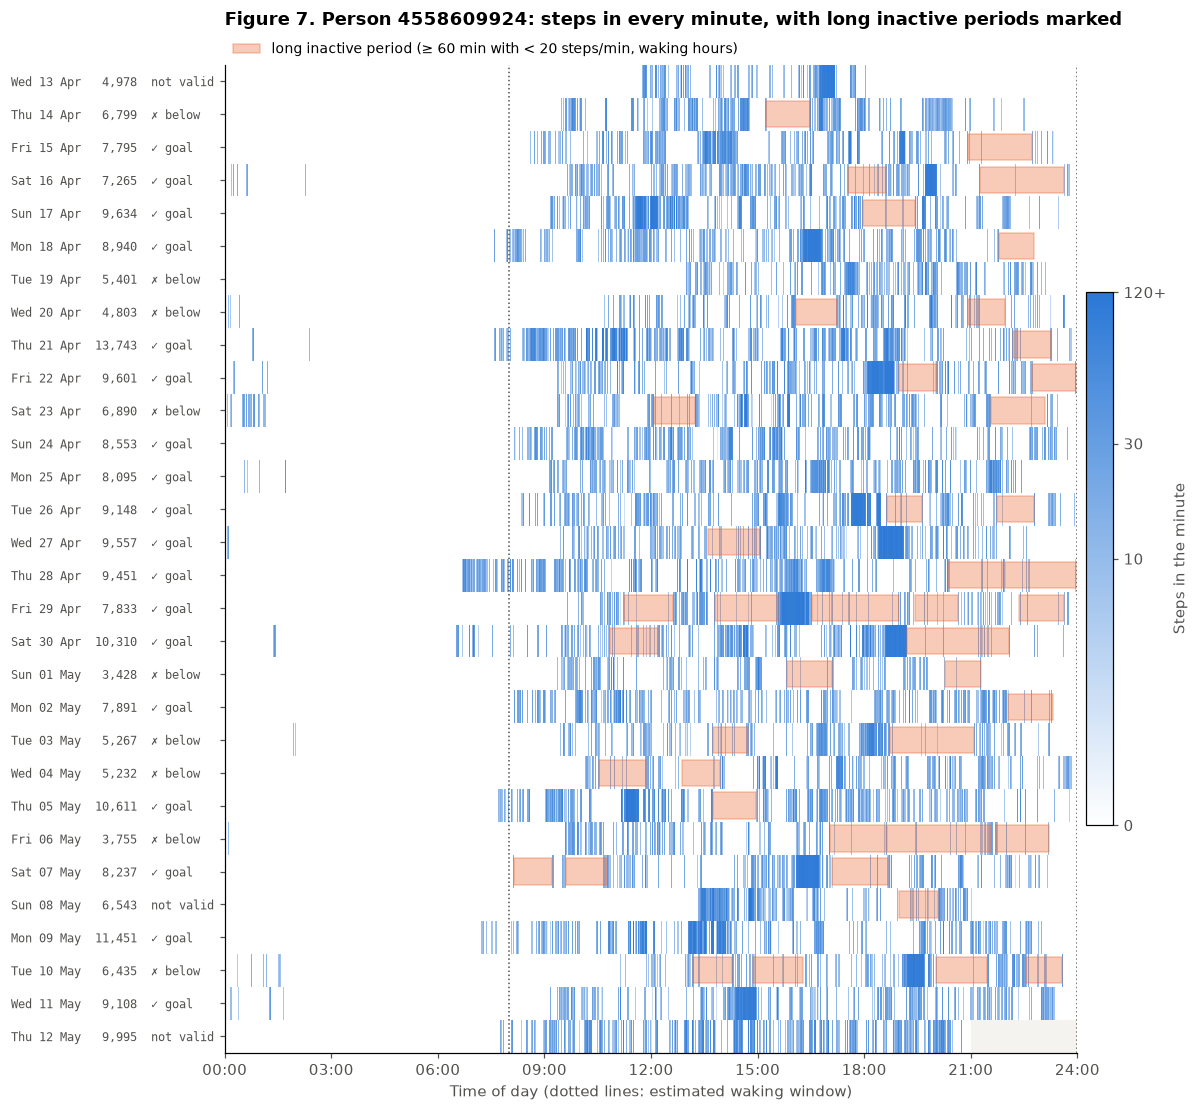

,Id 4558609924
valid days: goal / other,18 / 9
median steps: goal / other,"9,128 / 5,267"
median minutes in long inactive periods: goal / other,87.5 / 144
median first step: goal / other,08:15 / 09:34
"rank correlation, long-inactive minutes vs steps",-0.33
share of extra steps from more walking minutes,73%


In [20]:
def plot_person_month(result, pid):
    """Figure 7: one row per day, minute-by-minute steps, long inactive periods in orange."""
    person_days = result["days"].loc[pid]
    person_minutes = minutes[minutes["Id"] == pid]
    grid = person_minutes.pivot_table(
        index="Day", columns=person_minutes["Hour"] * 60 + person_minutes["Timestamp"].dt.minute, values="Steps"
    ).reindex(index=person_days.index, columns=range(1440))
    cmap = LinearSegmentedColormap.from_list("steps", ["#ffffff", GOAL_COLOUR])
    cmap.set_bad(NO_DATA_COLOUR)
    fig, ax = plt.subplots(figsize=(11, 0.28 * len(person_days) + 1.8))
    image = ax.imshow(np.log1p(grid), aspect="auto", cmap=cmap, vmin=0, vmax=np.log1p(120),
                      extent=(0, 24, len(person_days) - 0.5, -0.5), interpolation="nearest")
    row_of = {day: i for i, day in enumerate(person_days.index)}
    for bout in result["bouts"][result["bouts"]["Id"] == pid].itertuples():
        start = bout.Start.hour + bout.Start.minute / 60
        ax.add_patch(Rectangle((start, row_of[bout.Day] - 0.4), bout.Minutes / 60, 0.8,
                               facecolor=MISS_COLOUR, alpha=0.35, edgecolor=MISS_COLOUR, linewidth=1))
    wake = result["wake"][pid]
    for hour in (wake, wake + DEFS.waking_hours):
        ax.axvline(hour, color=TEXT_COLOUR, linestyle=":", linewidth=1)
    status = np.where(~person_days["Valid"], "not valid", np.where(person_days["Goal"], "✓ goal", "✗ below"))
    labels = [f"{day:%a %d %b} {steps:>7,}  {s:<9}" for day, steps, s in zip(person_days.index, person_days["Steps"], status)]
    ax.set_yticks(range(len(person_days)), labels, fontsize=8, family="DejaVu Sans Mono")
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
    ax.set_xlabel("Time of day (dotted lines: estimated waking window)")
    ax.set_title(f"Figure 7. Person {pid}: steps in every minute, with long inactive periods marked", loc="left", pad=26)
    cbar = fig.colorbar(image, ax=ax, pad=0.01, fraction=0.03)
    cbar.set_ticks(np.log1p([0, 10, 30, 120]), labels=["0", "10", "30", "120+"])
    cbar.set_label("Steps in the minute")
    ax.legend(handles=[Patch(facecolor=MISS_COLOUR, alpha=0.35, edgecolor=MISS_COLOUR,
                             label="long inactive period (≥ 60 min with < 20 steps/min, waking hours)")],
              loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9, borderaxespad=0.2)
    plt.tight_layout()
    plt.show()


plot_person_month(result, EXAMPLE_ID)
def clock(hours):
    """Decimal hours as hh:mm."""
    return f"{int(hours):02d}:{round(hours % 1 * 60):02d}"


ex = within.loc[EXAMPLE_ID]
pd.Series(
    {
        "valid days: goal / other": f"{ex['goal days']:.0f} / {ex['other days']:.0f}",
        "median steps: goal / other": f"{ex['Steps (goal)']:,.0f} / {ex['Steps (other)']:,.0f}",
        "median minutes in long inactive periods: goal / other": f"{ex['LongBoutMinutes (goal)']:.1f} / {ex['LongBoutMinutes (other)']:.0f}",
        "median first step: goal / other": f"{clock(ex['FirstStepHour (goal)'])} / {clock(ex['FirstStepHour (other)'])}",
        "rank correlation, long-inactive minutes vs steps": f"{ex['rank corr']:.2f}",
        "share of extra steps from more walking minutes": f"{ex['share of gap from more walking minutes']:.0%}",
    },
    name=f"Id {EXAMPLE_ID}",
).to_frame()

**What to see in Figure 7:** each row is one day of Id 4558609924. Blue streaks are walking and the orange boxes are long inactive periods. On most goal days (✓) the orange boxes come in the evening, after a day of frequent walking streaks. Several days below the goal (✗) start late (19 Apr around 13:00; 20 Apr and 10 May after 10:30), and on **Fri 06 May** (3,755 steps) there is almost no walking after 17:00. Some goal days still have several long periods: on Fri 29 Apr a burst of walking around 15:00–16:30 carries the day past 7,000. The table under the figure gives this person's numbers: 144 → 87.5 minutes in long inactive periods, and about 73% of their extra steps from more walking minutes.

## 14. Robustness: do the conclusions depend on my definitions?

**Step:** rerun the whole pipeline with one definition changed at a time, and record the headline numbers from Parts A and B.

In [21]:
settings = {
    "my definitions": DEFS,
    "long period >= 30 min": replace(DEFS, long_bout_min=30),
    "long period >= 90 min": replace(DEFS, long_bout_min=90),
    "inactive = exactly 0 steps/min": replace(DEFS, inactive_max_steps=0),
    "valid day >= 8 hours with steps": replace(DEFS, min_valid_hours=8),
    "valid day >= 12 hours with steps": replace(DEFS, min_valid_hours=12),
    "14-hour waking window": replace(DEFS, waking_hours=14),
}


def headline_numbers(defs):
    """The key Part A and Part B numbers for one set of definitions."""
    res = q1.analyse(minutes, daily, defs)
    people = q1.person_summary(res)
    rated_people = people[people["valid days"] >= defs.min_valid_days]
    comp = q1.within_person(res)
    fewer = int((comp["long-inactive min difference"] < 0).sum())
    return {
        "people with a verdict": len(rated_people),
        "meet 'most days'": int(rated_people["verdict"].str.startswith("yes").sum()),
        "clearly": int((rated_people["verdict"] == "yes (clearly)").sum()),
        "Part B people": len(comp),
        "less long inactivity on goal days": fewer,
        "sign test P": round(q1.sign_test(fewer, len(comp)), 4),
        "median change (min)": comp["long-inactive min difference"].median(),
        "share from more walking minutes": comp["share of gap from more walking minutes"].median(),
    }


sensitivity = pd.DataFrame({name: headline_numbers(defs) for name, defs in settings.items()}).T
count_columns = [c for c in sensitivity.columns if c not in ("sign test P", "median change (min)", "share from more walking minutes")]
sensitivity.astype({c: int for c in count_columns}).style.format(
    {"sign test P": "{:.4f}", "median change (min)": "{:.0f}", "share from more walking minutes": "{:.0%}"}
)

,people with a verdict,meet 'most days',clearly,Part B people,less long inactivity on goal days,sign test P,median change (min),share from more walking minutes
my definitions,29,22,14,21,18,0.0015,-91,73%
long period >= 30 min,29,22,14,21,17,0.0072,-88,73%
long period >= 90 min,29,22,14,21,19,0.0002,-84,73%
inactive = exactly 0 steps/min,29,22,14,21,14,0.1892,-45,58%
valid day >= 8 hours with steps,30,20,13,21,18,0.0015,-91,73%
valid day >= 12 hours with steps,29,22,14,20,18,0.0004,-104,73%
14-hour waking window,29,22,14,21,19,0.0002,-91,73%


**Interpretation:**

- **Part A is stable.** 20 to 22 people meet "most days" under every rule, and 13 to 14 do so clearly.
- **Part B holds for every reasonable threshold.** With a long period of 30, 60 or 90 minutes, a 14-hour window, or a valid-day rule of 8 or 12 hours, 17 to 19 of about 21 people have less long inactivity on goal days, and P stays below 0.01. In Checkpoint 2 the 90-minute threshold weakened the result for one person, but across 21 people it does not.
- **The exception is the "exactly 0 steps" rule**, where only 14 of 21 people show the pattern (P = 0.19). Under that rule a single step ends an inactive period, so a person who shifts in their chair every 20 minutes never has a "long" period. I think the 0–19 rule (Tudor-Locke et al., 2018) is a better match for *inactivity*, but this choice is the main assumption behind Part B.
- **The share of extra steps from more walking minutes** stays at about 73% under every definition except the 0-step rule, where "walking" includes any minute with a single step.

## 15. Answer to the driving problem

**Do they achieve at least 7,000 steps on most days by avoiding long periods of inactivity?**

**Part A: yes, for most people.** Of the 29 people with at least 10 valid days, **22 (76%)** reached 7,000 steps on more than half of their valid days, **14** of them clearly (the 95% interval lies above 50%). Only **14 (48%)** reached the stricter 5 days in 7. Four people with too few valid days get no verdict; all four had low step counts on the days they wore the tracker.

**Part B: yes, but by *interrupting* long inactive periods rather than being inactive less.**

- On their goal days, **18 of 21** people spent less time in long inactive periods than on their own other days, by a median of **91 minutes** (sign test P = 0.0015). This holds for every threshold from 30 to 90 minutes.
- Total inactive time barely changes (median −54 minutes, and it is *higher* for 8 of 21 people). What changes is that **short inactive spells increase for 20 of 21 people**: walking breaks long periods into short ones.
- The extra steps come mainly from **more walking minutes** (×1.9) rather than faster walking (×1.2), about 73% of the gap for the median person.
- Long inactive periods are **reduced, not avoided**. A typical goal day still has two of them, and only 14% of goal days have none.
- Between people, a lot of long inactivity does not stop someone reaching 7,000 steps (Figure 6). The pattern is about each person's own good and bad days.

**In one sentence:** most people in this dataset reach 7,000 steps on most days, and on the days they do, they break up their long inactive periods with extra walking, although they are not inactive for less time overall.

**How adherence affects the answer.** The share of goal days depends on which days count: 54% of all daily-file days, but 65% of valid days. The answer is therefore about days the tracker was worn for most of the day. Excluding the 4 low-adherence people probably makes the group look slightly more active than it is.

**Review of predictions**

| Prediction | Outcome |
|---|---|
| P1: 60–70% of people meet "most days" | **Confirmed, slightly exceeded:** 22 of 29 (76%) |
| P2: about 40% meet 5 days in 7 | **Roughly confirmed:** 14 of 29 (48%) |
| P3: most people have less long inactivity on goal days; weak link | **Confirmed:** 18 of 21; moderate link within people (median ρ = −0.40) |
| P4: extra steps mainly from more walking minutes | **Confirmed:** about 73% for the median person |
| P5: the valid-day rule raises the share of goal days | **Confirmed:** 54% → 65% |

**Limitations**

- **Association, not cause.** It could be that people walk more on busy days, and walking breaks up their sitting as a side effect. The data cannot show whether deliberately breaking up sitting *produces* a goal day.
- **Inactive or not worn?** Steps alone cannot tell sitting from a tracker on the desk. The valid-day rule and the first-to-last-step window reduce this problem but do not remove it.
- **Definitions.** The 60-minute and 0–19 steps/min thresholds are my choices. Part B depends mainly on the cadence rule (Section 14).
- **Sample.** 33 Amazon Mechanical Turk volunteers in 2016, for one month, with different Fitbit models. They are not a representative sample, and one month may not reflect usual behaviour.

## 16. References

- Australian Government Department of Health, Disability and Ageing. (n.d.). *Physical activity and exercise guidelines for all Australians: For adults (18 to 64 years)*. https://www.health.gov.au/topics/physical-activity-and-exercise/physical-activity-and-exercise-guidelines-for-all-australians/for-adults-18-to-64-years
- Furberg, R., Brinton, J., Keating, M., & Ortiz, A. (2016). *Crowd-sourced Fitbit datasets 03.12.2016–05.12.2016* [Data set]. Zenodo. https://doi.org/10.5281/zenodo.53894 (via Kaggle "FitBit Fitness Tracker Data", CC0: Public Domain, https://www.kaggle.com/datasets/arashnic/fitbit)
- Paluch, A. E., Bajpai, S., Bassett, D. R., Carnethon, M. R., Ekelund, U., Evenson, K. R., … Fulton, J. E. (2022). Daily steps and all-cause mortality: A meta-analysis of 15 international cohorts. *The Lancet Public Health, 7*(3), e219–e228. https://doi.org/10.1016/S2468-2667(21)00302-9
- Tang, L. M., Meyer, J., Epstein, D. A., Bragg, K., Engelen, L., Bauman, A., & Kay, J. (2018). Defining adherence: Making sense of physical activity tracker data. *Proceedings of the ACM on Interactive, Mobile, Wearable and Ubiquitous Technologies, 2*(1), Article 37. https://doi.org/10.1145/3191769
- Tudor-Locke, C., Han, H., Aguiar, E. J., Barreira, T. V., Schuna, J. M., Jr., Kang, M., & Rowe, D. A. (2018). How fast is fast enough? Walking cadence (steps/min) as a practical estimate of intensity in adults: A narrative review. *British Journal of Sports Medicine, 52*(12), 776–788. https://doi.org/10.1136/bjsports-2017-097628
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

## 17. Process notebooks and reuse

| Product notebook part | Based on | Change made for the product notebook |
|---|---|---|
| `q1.to_long`, `q1.day_table` | `person_minutes`, `day_table` (Checkpoint 2) | All 33 people at once; walking minutes added |
| `q1.estimate_waking_start`, `q1.inactive_runs` | Same names (Checkpoint 2) | Vectorised over people; also return awake minutes and first-step time |
| Adherence rules (Section 7) | `adherence_table` (Checkpoint 2) | Population level; counts people who meet "most days" |
| Figure 7 | `plot_day_timeline` (Checkpoint 2) | Uses the all-people pipeline |
| Data checks (Sections 5–6) | Data-quality and manual-scrutiny work (Checkpoint 1) | Hourly vs minute check added; daily-file differences explained |
| Within-person tests, Figures 1–6, decomposition | New in the product notebook | |

## 18. GenAI usage

**Tool:** Claude (Anthropic), used through the Claude Code assistant in VS Code, for my individual checkpoints and for this product notebook, the `q1_steps.py` module and drafts of the wiki pages. GenAI use is allowed for this assignment; this section documents it.

**How GenAI was used**

- **Code drafting.** Claude generalised the per-person functions from my Checkpoint 2 notebook into `q1_steps.py` so they run for all 33 people at once, and drafted the plotting cells.
- **Text drafting.** Claude drafted the markdown explanations. The definitions and predictions come from my Checkpoint 1 and 2 notebooks.
- **Checking.** Claude checked the notebook against each point of the assignment specification and rubric.
- **Results.** Every number in the text was taken from the cell outputs after running the notebook, not written from memory.

**A typical cell creation process: Section 11, "goal days swap long inactive periods for short spells"**

1. **Prompt.** I asked Claude to complete the remaining parts of the project to the rubric's highest standard, using my Checkpoint 2 notebook and the assignment specification as context.
2. **Regression check first.** Before any new analysis, the rewritten all-people pipeline was run on Id 4558609924 and compared with my Checkpoint 2 results. It reproduced them exactly: 27 valid days, 18 goal days, waking window from 08:00, median 144 vs 87.5 minutes in long inactive periods, rank correlation −0.33.
3. **Iteration driven by an output.** The first within-person comparison (Section 10) showed about 90 fewer minutes in long inactive periods on goal days, but only about 70–80 more walking minutes. The obvious next prompt was *"where did the rest of the time go?"* That led to adding `InactiveMinutes` to `q1.analyse` and splitting inactive time into short spells and long periods. The split showed that total inactivity hardly changes, which became the main finding.
4. **Hand checks.** The sign-test P-value for 18 of 21 was checked by hand: $2 \times (1 + 21 + 210 + 1330)/2^{21} \approx 0.0015$. The decomposition in Section 12 is an exact identity per day, so the two parts must add up to the total gap.
5. **Robustness before writing.** The interpretation was written only after Section 14 showed that the finding holds for thresholds of 30–90 minutes, and fails only for the strict 0-step rule. That limitation is stated in Sections 14 and 15.
6. **My review and manual edits.** ✏️ *Ritishka: before submitting, replace this bullet with what you changed after reading and running the notebook yourself (for example wording you rewrote, a threshold you questioned, or a figure label you fixed).*

**Reflection on GenAI use.** GenAI was fastest at reshaping pandas code and at checking work against the specification. It was most useful when each output was checked against something I already knew (my Checkpoint 2 numbers). Its suggestions had to be tested, not trusted: the most important finding came from questioning an intermediate output, not from the first answer.